## Message's In LangGraph ##

In [11]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()

if os.environ['OPENAI_API_KEY']:
    print("Openai key is set")
else:
    raise ValueError("openAi key is not set")


llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)



Openai key is set


In [12]:
from typing import TypedDict,List,Annotated

class graph_schema(TypedDict):
    msg_man:List
    

In [13]:
## Node

from langchain_core.messages import AIMessage
def create_post(scham:graph_schema)->graph_schema:
    msg_man=scham['msg_man']
    ai_respo = llm_openai.invoke(msg_man).content
    ai_respo_msg = AIMessage(content=ai_respo)
    scham['msg_man'] = msg_man + [ai_respo_msg]

    return scham

def currect_post (schma:graph_schema)-> graph_schema:
    msg_man=schma['msg_man']
    ai_respo=llm_openai.invoke(msg_man).content
    ai_respo_msg = AIMessage(content=ai_respo)
    schma['msg_man']= msg_man + [ai_respo_msg]
    return schma



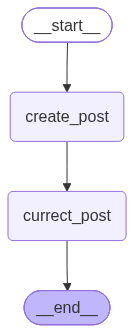

In [14]:
# Connect state graph AND check the img
from langgraph.graph import StateGraph, START , END

graph = StateGraph(graph_schema)

graph.add_node("create_post",create_post)
graph.add_node('currect_post',currect_post)

graph.add_edge(START,'create_post')
graph.add_edge('create_post','currect_post')
graph.add_edge('currect_post',END)

from IPython.display import Image,display
final_graph= graph.compile()

Image(final_graph.get_graph().draw_mermaid_png())

In [ ]:
## Run the flow 
from langchain_core.messages import HumanMessage

final_graph.invoke(
    {
        'msg_man':[HumanMessage(content="Till me information about ai agnet")]
    }
)

{'msg_man': ['Till me information about ai agnet',
  AIMessage(content='I think you mean “Tell me information about AI agent.” Here’s a concise, practical overview covering what an AI agent is, how it works, common types, use cases, development considerations, tools, and safety/ethical issues. Tell me if you want more detail on any part (e.g., building one, code examples, RL agents, multi-agent systems).\n\nWhat is an AI agent?\n- An AI agent is any software (or software+hardware) system that perceives its environment through sensors, makes decisions, and takes actions through actuators to achieve goals. It can be simple (a rule-based chatbot) or complex (an autonomous car).\n\nCore components\n- Sensors / perception: collect data (cameras, microphones, APIs, logs).\n- State or world model: representation of what the agent thinks the environment currently is.\n- Decision-making (policy): maps states or perceptions to actions (rules, heuristics, learned models).\n- Actuators / actions: 